# Preprocesamiento — limpieza y regularización (v5 → v6)
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Rosario

Este cuaderno **ejecuta y documenta** el preprocesamiento a nivel dataset que lleva la muestra
analítica de **v5** a **v6**. Es el paso posterior al EDA y previo al *feature engineering*.

El alcance es deliberadamente acotado: **limpieza y regularización de nombres**. No se imputan
faltantes ni se recortan outliers — esas transformaciones se **aprenden dentro de cada *fold***
(Kuhn & Johnson, 2013) y van en el pipeline de modelado, no como una transformación única del
dataset. Acá se resuelven los tres problemas que el EDA dejó señalados: el HTML/boilerplate en las
descripciones, el campo `antiguedad` sucio, y la convención de nombres `eda_*` incompleta.

Como el del EDA, es **estático y reproducible**: se ejecuta de punta a punta y se renderiza en
GitHub/nbviewer sin necesidad de descargar el repositorio.

### Entorno y dependencias

```
pip install pandas numpy matplotlib seaborn
```

In [25]:
# ── Configuración y carga ─────────────────────────────────────────────────
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT = "#2c6e91", "#c0562b", "#3a8f5e"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5,
                     "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_eda_centro_v5.csv.gz")
print(f"Muestra v5: {len(df):,} avisos · {df.shape[1]} columnas")

Muestra v5: 4,765 avisos · 124 columnas


### Controles de validez de la muestra de entrada

El **filtrado por alcance** (moneda, distrito, fecha de publicación) y el descarte de **valores
basura** se resolvieron **aguas arriba** —en las etapas de auditoría y validación previas
(documentadas en `docs/PIPELINE.md`) y en el corte temporal que definió v5—, no en este cuaderno. Aquí solo **verificamos que esos controles se cumplen** en la
muestra que recibimos, para dejar constancia de que la limpieza que sigue parte de datos ya
validados (buena práctica del preprocesamiento clásico, que estos controles hacían de forma
explícita).

In [26]:
p = pd.to_numeric(df["eda_precio_usd"], errors="coerce")
es_usd = (df["precio_moneda"] == "USD")
es_centro = (df["eda_distrito"] == "CENTRO")
ant = pd.to_numeric(df["antiguedad_aviso_dias"], errors="coerce")
ok = lambda cond: "✓" if cond else "✗ REVISAR"
controles = pd.DataFrame([
    ("Target sin valores basura",        f"mín USD {p.min():,.0f}",             ok(p.min() > 1000)),
    ("Moneda = USD",                     f"{es_usd.mean()*100:.0f}%",           ok(es_usd.all())),
    ("Ubicación = Distrito Centro",      f"{es_centro.mean()*100:.0f}%",        ok(es_centro.all())),
    ("Antigüedad del aviso ≤ 6 meses",   f"máx {ant.max():.0f} días",           ok(ant.max() <= 183)),
], columns=["control", "resultado", "estado"])
display(controles)

,control,resultado,estado
0,Target sin valores basura,"mín USD 23,000",✓
1,Moneda = USD,100%,✓
2,Ubicación = Distrito Centro,100%,✓
3,Antigüedad del aviso ≤ 6 meses,máx 183 días,✓


Los cuatro controles pasan: el target no tiene basura (mínimo muy por encima de valores
espurios), la muestra es **100% en USD** y **100% del Distrito Centro**, y ningún aviso supera los
**6 meses** de antigüedad. Es decir, los filtros de las etapas previas **se sostienen** en la entrada
de este cuaderno.

## 1. Saneo de las descripciones

El EDA mostró que `descripcion_completa` arrastra **HTML residual** y la **leyenda legal del
corredor** (código civil, ley de lealtad comercial, defensa del consumidor, intermediación), al punto
de que los trigramas más frecuentes eran íntegramente esa leyenda, no contenido del inmueble. Ese
ruido contaminaría cualquier feature de texto. Creamos **`descripcion_limpia`** quitando etiquetas
HTML, entidades y los segmentos con la leyenda legal; el campo original se conserva para
trazabilidad.

In [27]:
_LEGAL = re.compile(r"(corredor|corretaje|matr[ií]cula|cucicba|colegio de corredores|"
                    r"lealtad comercial|c[oó]digo civil|defensa del consumidor|"
                    r"intermediaci[oó]n|operaciones inmobiliarias)", re.I)
_JUNK = re.compile(r"\b(ver datos|descripciondatosanunciante|span|btn|href|button)\b", re.I)

def limpiar_descripcion(t):
    t = re.sub(r"<[^>]+>", " ", str(t))            # etiquetas HTML
    t = re.sub(r"&[a-z#0-9]+;", " ", t)             # entidades HTML
    seg = re.split(r"[\n\r]+|(?<=[.;])\s+", t)       # por líneas y oraciones
    seg = [s for s in seg if not _LEGAL.search(s)]   # quita la leyenda legal
    return re.sub(r"\s+", " ", _JUNK.sub(" ", " ".join(seg))).strip()

d = df["descripcion_completa"].astype(str)
print(f"Avisos con HTML: {d.str.contains(r'<[^>]+>').mean()*100:.0f}%  ·  "
      f"con leyenda legal: {d.str.lower().str.contains('corredor|lealtad comercial').mean()*100:.0f}%")

df["descripcion_limpia"] = d.map(limpiar_descripcion)

# ejemplo antes/después (aviso con leyenda legal)
i = df[d.str.lower().str.contains("corredor")].index[0]
print("\n--- ANTES (fragmento final) ---\n", df.loc[i, "descripcion_completa"][-320:])
print("\n--- DESPUÉS (fragmento final) ---\n", df.loc[i, "descripcion_limpia"][-320:])

Avisos con HTML: 12%  ·  con leyenda legal: 26%

--- ANTES (fragmento final) ---
 revio aviso. La información proporcionada no compromete contractualmente a nuestra empresa.
Todas las operaciones son concretadas por un Corredor Inmobiliario Matriculado vinculado a nuestra firma. SANSÓ Propiedades no ofrece ningún tipo de servicio gratuito, todas las prestaciones profesionales son de carácter oneroso

--- DESPUÉS (fragmento final) ---
 ción correspondiente, no constituyendo oferta alguna. Los precios mencionados pueden verse alterados sin previo aviso. La información proporcionada no compromete contractualmente a nuestra empresa. SANSÓ Propiedades no ofrece ningún tipo de servicio gratuito, todas las prestaciones profesionales son de carácter oneroso


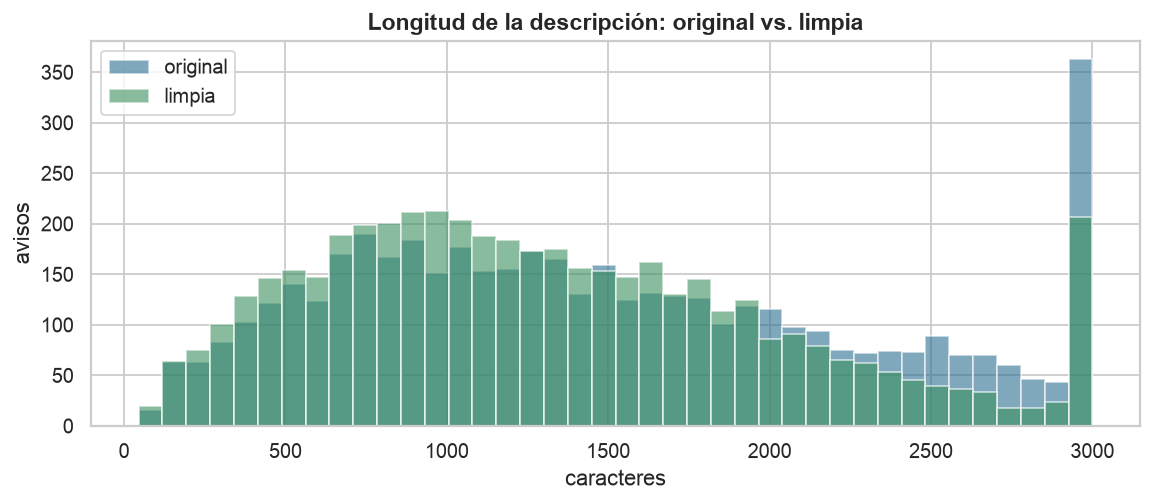

Reducción media de longitud: 10%


In [28]:
# reducción de longitud por el saneo
larg_antes = d.str.len(); larg_desp = df["descripcion_limpia"].str.len()
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(larg_antes.clip(upper=3000), bins=40, alpha=.6, color=PAL, label="original")
ax.hist(larg_desp.clip(upper=3000), bins=40, alpha=.6, color=ACCENT, label="limpia")
ax.set(title="Longitud de la descripción: original vs. limpia", xlabel="caracteres", ylabel="avisos")
ax.legend(); plt.show()
print(f"Reducción media de longitud: {(1 - larg_desp/larg_antes.replace(0,np.nan)).mean()*100:.0f}%")

El saneo elimina la leyenda legal y el markup sin tocar el contenido descriptivo: la reducción
de longitud es moderada (concentrada en los avisos que sí traían boilerplate). `descripcion_limpia`
es el insumo con el que se (re)generarán los indicadores `feat_*` en la etapa de feature
engineering.

## 2. Limpieza de `antiguedad`

El campo mezcla **años numéricos** con **categorías** ('A estrenar', 'En construcción') y arrastra
algún **valor imposible** (en el EDA apareció un "792"). Lo separamos en dos variables limpias:
`eda_antiguedad_anos` (numérica) y `eda_antiguedad_estado` (categórica), marcando como inválidos los
valores fuera de un rango plausible (0–150 años).

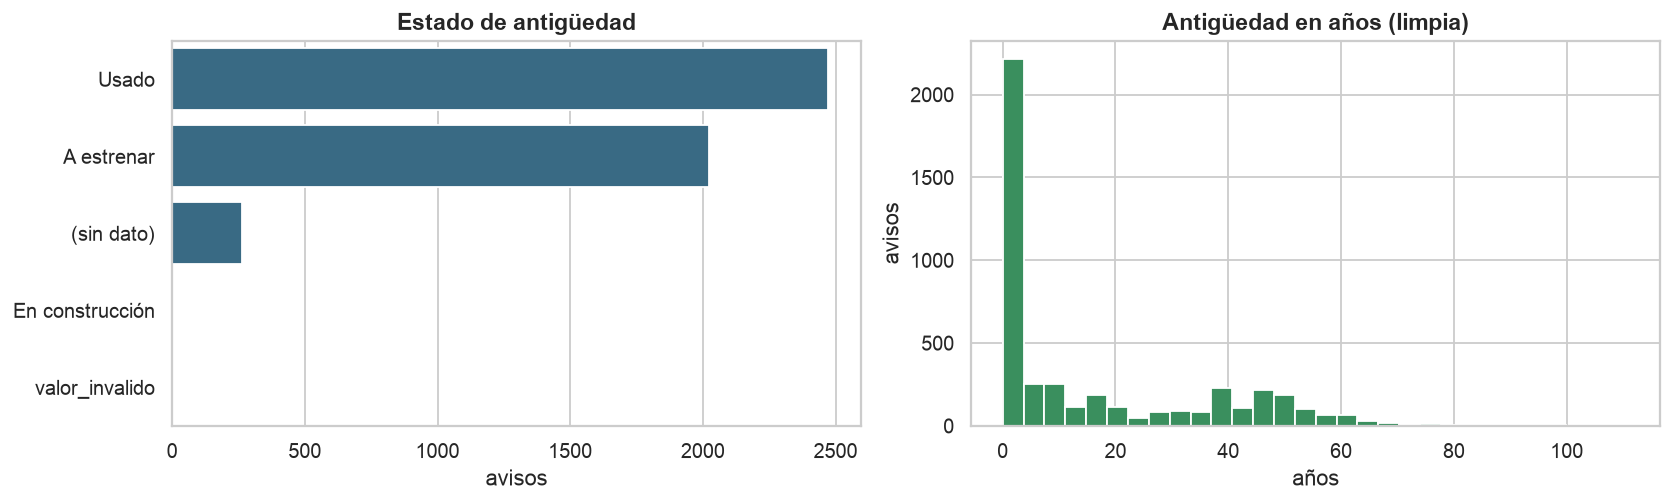

inválidos marcados (anos=NA): 1 · cobertura años: 94%


In [29]:
def parse_antiguedad(v):
    s = str(v).strip().lower()
    if s in ("", "nan", "none"): return np.nan, None
    if "estrenar" in s: return 0.0, "A estrenar"
    if "construc" in s: return np.nan, "En construcción"
    try: y = float(s.replace(",", "."))
    except ValueError: return np.nan, None
    if 0 <= y <= 150: return y, ("A estrenar" if y == 0 else "Usado")
    return np.nan, "valor_invalido"          # imposibles (p. ej. 792)

# fuente: la versión auditada; cae a la cruda si falta
fuente = df["antiguedad_auditada"].where(df["antiguedad_auditada"].notna(), df["antiguedad"])
par = fuente.map(parse_antiguedad)
df["eda_antiguedad_anos"] = par.map(lambda t: t[0])
df["eda_antiguedad_estado"] = par.map(lambda t: t[1])

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
est = df["eda_antiguedad_estado"].fillna("(sin dato)").value_counts()
sns.barplot(x=est.values, y=est.index, color=PAL, ax=axs[0])
axs[0].set(title="Estado de antigüedad", xlabel="avisos", ylabel="")
axs[1].hist(df["eda_antiguedad_anos"].dropna(), bins=30, color=ACCENT, edgecolor="white")
axs[1].set(title="Antigüedad en años (limpia)", xlabel="años", ylabel="avisos")
plt.show()
print("inválidos marcados (anos=NA):", int((df['eda_antiguedad_estado']=='valor_invalido').sum()),
      "· cobertura años:", f"{df['eda_antiguedad_anos'].notna().mean()*100:.0f}%")

Queda un campo numérico usable (0–~110 años) más un estado interpretable. Los valores
imposibles quedan marcados y en `NA`, no borrados, para no perder la fila y poder auditarlos.

## 3. Regularización de nombres

El EDA dejó en evidencia que la convención `eda_*` (columna lista para el modelo) estaba **aplicada
de forma incompleta**: variables como `ambientes`, `dormitorios`, `disposicion` u `orientacion` se
usaban crudas. Para que valga la regla simple **"el modelo consume `eda_*` y `feat_*`"**, creamos las
versiones `eda_` que faltaban (el original se conserva) y renombramos un feature confuso.

In [30]:
copias = {"eda_ambientes": "ambientes", "eda_dormitorios": "dormitorios",
          "eda_disposicion": "disposicion", "eda_orientacion": "orientacion",
          "eda_tipo_operacion": "tipo_operacion", "eda_toilette": "toilette"}
for nuevo, base in copias.items():
    df[nuevo] = df[base]

# feat_litoral_gas → feat_gas_natural (no es la empresa; captura conexión a gas natural)
if "feat_litoral_gas" in df.columns:
    df = df.rename(columns={"feat_litoral_gas": "feat_gas_natural"})

mapa = pd.DataFrame(
    [(k, v) for k, v in copias.items()] +
    [("eda_antiguedad_anos / eda_antiguedad_estado", "antiguedad (limpiada)"),
     ("feat_gas_natural", "feat_litoral_gas (renombrada)")],
    columns=["columna nueva", "origen"])
display(mapa)
print("feat_gas_natural:", "feat_gas_natural" in df.columns,
      "| feat_litoral_gas eliminada:", "feat_litoral_gas" not in df.columns)

,columna nueva,origen
0,eda_ambientes,ambientes
1,eda_dormitorios,dormitorios
2,eda_disposicion,disposicion
3,eda_orientacion,orientacion
4,eda_tipo_operacion,tipo_operacion
5,eda_toilette,toilette
6,eda_antiguedad_anos / eda_antiguedad_estado,antiguedad (limpiada)
7,feat_gas_natural,feat_litoral_gas (renombrada)


feat_gas_natural: True | feat_litoral_gas eliminada: True


A partir de v6, el contrato de nombres es limpio: las columnas que consume el modelo llevan
prefijo `eda_` (numéricas/categóricas) o `feat_` (binarias de texto), y todo lo demás —crudas,
`*_auditado`, flags— queda como trazabilidad.

## 4. Política de faltantes (documentada, sin imputar)

Se distingue **ausencia estructural** de **faltante genuino** (Rubin, 1976; Kuhn & Johnson, 2019):
`eda_cocheras` o `eda_expensas` en `NA` suelen indicar *ausencia* (sin cochera / no informa
expensas), no un dato perdido. Por eso **no imputamos a nivel dataset**: la imputación se aprende
dentro del fold y, cuando corresponda, se acompaña de indicadores de 'informado'.

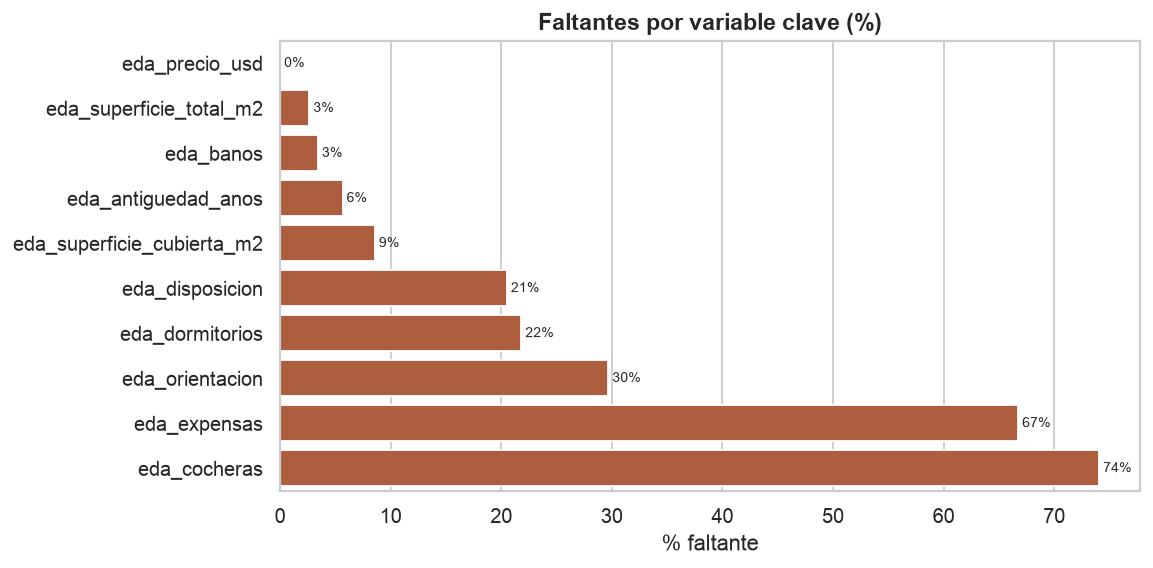

In [31]:
claves = ["eda_precio_usd","eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_banos",
          "eda_dormitorios","eda_antiguedad_anos","eda_disposicion","eda_orientacion",
          "eda_cocheras","eda_expensas"]
miss = (df[claves].isna().mean()*100).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=miss.values, y=miss.index, color=PAL2, ax=ax)
for i, v in enumerate(miss.values): ax.text(v, i, f" {v:.0f}%", va="center", fontsize=8)
ax.set(title="Faltantes por variable clave (%)", xlabel="% faltante", ylabel=""); plt.show()

El target no tiene faltantes. Las estructurales presentan niveles moderados; el caso saliente
son cocheras y expensas, faltantes en su mayoría por **ausencia estructural**, que probablemente
convenga modelar con un indicador de 'informado' antes que imputar un valor arbitrario.

## 5. Política de outliers (documentada, sin recortar)

Los valores atípicos se marcaron con la regla robusta **3·IQR** (Tukey, 1977) en el EDA. El recorte,
la winsorización o la exclusión se deciden en el modelado, con criterio de dominio y evaluando su
efecto fuera de muestra: muchos extremos son propiedades legítimamente premium, no errores. **No se
elimina nada a nivel dataset.**

## 6. Prevención de fuga de información (*data leakage*)

La razón por la que la **imputación, el *encoding* y el escalado no se hacen en esta etapa** sino
dentro del pipeline de modelado es **metodológica, no de conveniencia**: evitar la **fuga de
información**. Toda transformación que **estima parámetros a partir de los datos** —la media/mediana
de una imputación, la tabla de un *target/mean encoding*, la media y el desvío de un escalado, un λ de
Box-Cox, una selección de variables o un PCA— debe ajustarse **usando solo la porción de entrenamiento
de cada *fold*** y aplicarse a la porción retenida. Estimar esos parámetros sobre **todo** el dataset
antes de particionar filtra información del conjunto de validación/test y **sobreestima la
performance**.

Por eso distinguimos dos tipos de operación:

- **Determinísticas y por fila** (no miran a las otras observaciones): limpieza de HTML, parseo de
  `antiguedad`, `log(precio)`, `precio/m² = precio/superficie`, renombres. **No inducen fuga** y por
  eso se resuelven a nivel dataset — es exactamente lo que hace este cuaderno (v6).
- **Que estiman parámetros de la distribución**: imputación, *encoding*, estandarización, selección de
  variables, reducción de dimensionalidad. **Van dentro del *fold***, vía `Pipeline` /
  `ColumnTransformer` ajustados solo con el *train*.

Se complementa con el **split *group-aware*** por `property_id` / `building_cluster_id`, que evita la
otra fuente de fuga: la misma unidad (republicada) cayendo en *train* y *test*.

**Fundamento bibliográfico.** La referencia canónica es **Hastie, Tibshirani & Friedman — *ESL*,
§7.10.2** ("The Wrong and Right Way to Do Cross-Validation"), que muestra cómo preprocesar sobre todos
los datos antes de la validación cruzada puede dar error casi nulo **incluso con datos aleatorios**.
**Kuhn & Johnson (2013)** exige ajustar el preprocesamiento dentro del resampling; **James et al. —
*ISL*, cap. 5** y **Géron (2019), cap. 2** (`fit` solo con *train*, encapsulado en `Pipeline`) lo
operacionalizan; **Kuhn & Johnson (2019)** extiende el criterio a la selección de variables; y el
recaudo de republicaciones sigue a **Gutiérrez et al. (2026)**.

## 7. Guardar la muestra v6

In [32]:
df["preproc_version"] = 6
salida = ROOT / "data" / "processed" / "zonaprop_v2_eda_centro_v6.csv.gz"
# gzip determinístico (mtime=0): bytes idénticos a los del script → misma reproducibilidad
df.to_csv(salida, index=False, compression={"method": "gzip", "mtime": 0})
print(f"v6 escrito: {salida.relative_to(ROOT)}")
print(f"{len(df):,} filas · {df.shape[1]} columnas")

v6 escrito: data/processed/zonaprop_v2_eda_centro_v6.csv.gz
4,765 filas · 134 columnas


## Próximos pasos (feature engineering)

Con v6 lista, la etapa siguiente aborda: regenerar los `feat_*` desde `descripcion_limpia` y evaluar
nuevos atributos de texto; construir ratios derivados (cubierta/total, precio por ambiente) y
variables de microlocalización; y definir el *encoding* y la imputación **dentro del pipeline de
modelado** (por fold), junto con el *group-aware split* por `property_id`/`building_cluster_id`.

## Referencias

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), §7.10.2. Springer.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (cap. 5). Springer.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling* (cap. 3 y resampling). Springer.
- Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection*. CRC Press.
- Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow* (2ª ed., cap. 2). O'Reilly.
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- Gutiérrez et al. (2026). Antecedente argentino (Buenos Aires): identificación de republicaciones.
- *Complementarias (a incorporar a la biblioteca):* Kaufman, Rosset & Perlich (2012), "Leakage in Data Mining" (ACM TKDD); Kapoor & Narayanan (2023), "Leakage and the reproducibility crisis in ML-based science" (Patterns); scikit-learn — *Common pitfalls: data leakage* (Pedregosa et al., 2011).